[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GNash19/paminaw/blob/v1.0.0/notebooks/solutions/paminaw_workshop.ipynb)

# Paminaw! Teaching Machines to Listen in Cebuano and Tagalog (solutions)

**Speech Processing Using PyTorch** · PyCon Davao 2026 · Workshop 2 (MinNa LProc)<br>
Saturday 17 October 2026, 1:10–3:10 PM · Ateneo de Davao University<br>
Facilitators: **Nash Golosino** and **Aurora Manseras**
| Time | What |
|---|---|
| 1:10–1:40 | Overview talk |
| 1:40–1:55 | Q&A: open this notebook and run **cell 0** |
| 1:55–2:15 | **Lab 1** · Load & see |
| 2:15–2:45 | **Lab 2** · Transcribe (+ Lab 2b, MMS on a GPU runtime) |
| 2:45–3:05 | **Lab 3** · Score |
| 3:05–3:10 | Wrap-up |

**What you'll do.** You will load real Tagalog and Cebuano recordings from the FLEURS
dataset as PyTorch tensors, look at them as waveforms and mel spectrograms, and hear what
is lost at telephone quality. Then you will run OpenAI's Whisper on them, find out what it
does with Cebuano, a language it has no token for, and score the transcripts with WER and
CER. Along the way you will discover that the way text is cleaned up before scoring can
change which model "wins".

> **How to use this notebook.** Click a code cell and press **Shift+Enter**. Run cells
> from top to bottom. Every lab starts with its own *setup* cell, so if you fall behind,
> jump to the next lab and start there. A free CPU runtime is enough; a GPU runtime
> (Runtime → Change runtime type → T4 GPU) also runs Lab 2b live.

> All scores here are on the **workshop subset (100 clips per language)** of the FLEURS
> test split. They are **not** the paper's full-split numbers.

## 0 · Setup: run me first

This cell installs the workshop package `paminaw`, prints the versions of the libraries we
use, checks for a GPU and downloads the 200 audio clips. Wait for the **READY** line
(about a minute). If something fails, the message tells you how to fix it.

In [1]:
# Cell 0 · setup
import os
import subprocess
import sys

PAMINAW_REF = "v1.0.0"  # the workshop release on GitHub
SMOKE_TEST = os.environ.get("PAMINAW_SMOKE") == "1"  # quick test mode: 2 clips, whisper-tiny

if "google.colab" in sys.modules:
    print(f"Installing paminaw {PAMINAW_REF} ...")
    url = f"paminaw @ git+https://github.com/GNash19/paminaw@{PAMINAW_REF}"
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", url],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stderr[-1500:])
        raise SystemExit("Error: Could not install paminaw. Fix: check that Colab says "
                         "'Connected' (top right), then run this cell again.")
try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: paminaw is not installed. Fix: outside Colab, run "
                     "`pip install -e .` in the repo folder (see docs/OFFLINE.md).") from None

SETUP = paminaw.setup_workshop(smoke=SMOKE_TEST)

Versions: python 3.13.7 · torch 2.11.0+cpu · torchaudio 2.11.0+cpu · transformers 5.18.0 · datasets 4.8.5 · jiwer 4.0.0
No GPU: running on CPU. Everything works; Lab 2b will load precomputed MMS outputs. (Optional: Runtime → Change runtime type → T4 GPU.)
READY: 200 clips (100 Tagalog + 100 Cebuano, workshop subset) · cpu (float32) · 0 s


## 1 · Load & see (about 20 minutes)

A microphone measures air pressure thousands of times per second. Each measurement is a
**sample**, and the number per second is the **sample rate**. All our models expect
**16,000 samples per second (16 kHz)**. In PyTorch, a recording is a **tensor** of shape
`(channels, samples)`.

A **mel spectrogram** shows which frequencies are loud at each moment, grouped into 80
bands spaced the way human hearing spaces them. Taking the **log** makes quiet and loud
parts visible together. Whisper does not read the raw waveform; it reads exactly this
log-mel picture.

In [2]:
import os

try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: Run cell 0 (Setup) at the top of the notebook first.") from None

# Lab 1 setup: safe to run even if you skipped the cells above
import matplotlib.pyplot as plt
import torch
import torchaudio
from IPython.display import Audio, display

from paminaw.plotting import PALETTE, plot_mel, plot_waveform, set_style

SMOKE_TEST = os.environ.get("PAMINAW_SMOKE") == "1"
paminaw.set_seed()  # 20260814, the seed from the paper
set_style()  # large fonts for the projector
N = 2 if SMOKE_TEST else 100
tl = paminaw.load_subset("tagalog", n=N)
ceb = paminaw.load_subset("cebuano", n=N)
print(f"{len(tl)} Tagalog + {len(ceb)} Cebuano clips ready.")
tl[["fleurs_id", "duration_s", "transcription"]].head(3)

100 Tagalog + 100 Cebuano clips ready.


,fleurs_id,duration_s,transcription
0,1835,15.54,walang inilabas na babala ng tsunami at ayon s...
1,1969,19.56,ito ay nagsasaad na ang kadalasang epektibong ...
2,1928,20.28,noong taong 1976 tatlumpung porsiyento ng mach...


### The slide code: from a file to a log-mel spectrogram

Five lines take us from a file on disk to what the model sees.

In [3]:
path = tl.path[0]
print("Tagalog:", tl.transcription[0])

try:
    wav, sr = torchaudio.load(path)  # file → tensor + sample rate
except Exception:  # torchaudio.load needs TorchCodec + FFmpeg (Colab has both)
    wav, sr = paminaw.load_audio(path)  # same result, via soundfile

wav = wav.mean(dim=0, keepdim=True)  # stereo → mono, shape (1, samples)
if sr != 16_000:
    wav = torchaudio.functional.resample(wav, sr, 16_000)
mel = torchaudio.transforms.MelSpectrogram(sample_rate=16_000, n_fft=400, hop_length=160, n_mels=80)(wav)
log_mel = torch.log(mel + 1e-6)

print(f"sample rate: {sr} Hz · waveform {tuple(wav.shape)} · {wav.shape[1] / 16_000:.1f} s")
print(f"mel spectrogram {tuple(mel.shape)} = (channels, mel bands, frames)")

Tagalog: walang inilabas na babala ng tsunami at ayon sa ahensiya ng heopisika ng jakarta walang babala ng tsunami ang ilalabas dahil hindi naabot ng lindol ang lakas na 6.5 na kinakailangan
Note: torchaudio.load is not available here (it needs TorchCodec + FFmpeg), so paminaw is reading audio with soundfile instead. Results are identical.
sample rate: 16000 Hz · waveform (1, 248640) · 15.5 s
mel spectrogram (1, 80, 1555) = (channels, mel bands, frames)


**Reading the shapes.** `n_fft=400` looks at 400 samples (25 ms) at a time and
`hop_length=160` moves 160 samples (10 ms) each step, so a 10-second clip becomes about
1,000 frames of 80 numbers each. `+ 1e-6` keeps `log` away from `log(0)` in silent frames.

### Exercise 1 · Plot one Tagalog and one Cebuano waveform

Change `CLIP` to look at other recordings. **Question:** Can you see the pauses between phrases?
Which recording is longer?

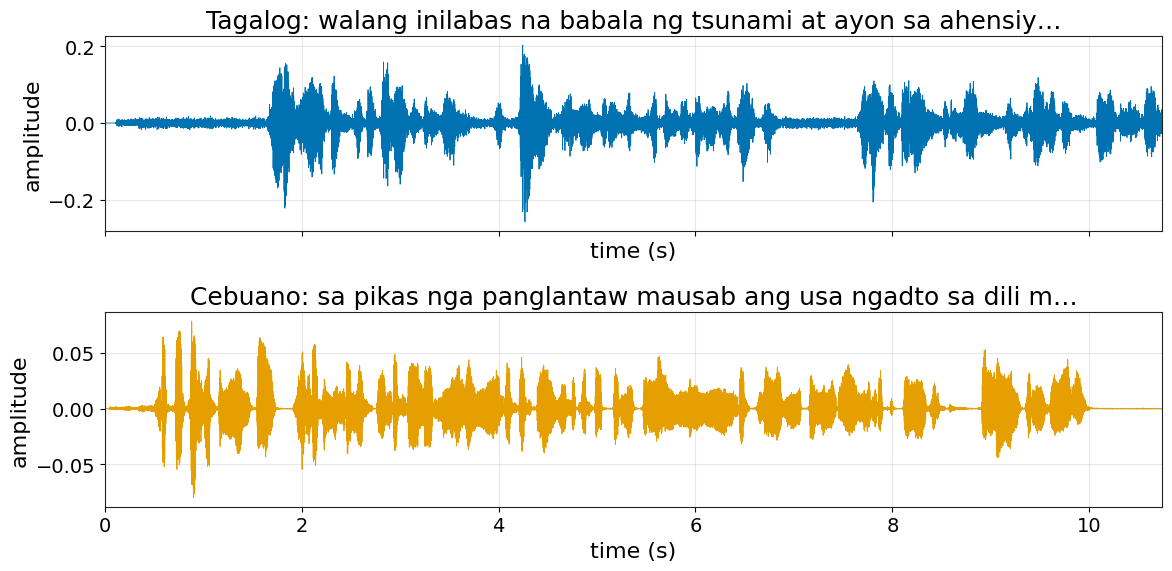

In [4]:
CLIP = 0  # try another number (0–99)

wav_tl = paminaw.load_16k_mono(tl.path[CLIP])
wav_ceb = paminaw.load_16k_mono(ceb.path[CLIP])

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
plot_waveform(wav_tl, title=f"Tagalog: {tl.transcription[CLIP][:55]}…", ax=axes[0])
plot_waveform(wav_ceb, title=f"Cebuano: {ceb.transcription[CLIP][:55]}…", ax=axes[1],
              color=PALETTE[1])
plt.tight_layout()
plt.show()

In [5]:
# Solution: durations, and where the pauses are (frames quieter than 2% of the peak)
for name, w in [("Tagalog", wav_tl), ("Cebuano", wav_ceb)]:
    frames = w[0, : w.shape[1] // 160 * 160].reshape(-1, 160).abs().max(dim=1).values
    quiet = (frames < 0.02 * frames.max()).float().mean().item()
    print(f"{name}: {w.shape[1] / 16_000:.1f} s long, {quiet:.0%} of 10 ms frames are near-silent")

Tagalog: 15.5 s long, 1% of 10 ms frames are near-silent
Cebuano: 10.7 s long, 20% of 10 ms frames are near-silent


**Answer.** Pauses show up as flat stretches near zero, mostly between phrases and at the
start and end of the recording. The length depends on the sentence and on the speaker;
In our subset the clips run from about 6 to 37 seconds, most of them 10–25 seconds.

### Exercise 2 · Listen at 16 kHz and at 8 kHz

Put your earphones on. Telephone audio is often 8 kHz: half as many samples, and nothing
above 4 kHz survives. **Question:** Which sounds change the most?

In [6]:
SECONDS = 6  # play only the first few seconds
clip16 = wav_ceb[:, : 16_000 * SECONDS]
clip8 = torchaudio.functional.resample(clip16, 16_000, 8_000)
print(f"16 kHz: {tuple(clip16.shape)} samples → 8 kHz: {tuple(clip8.shape)} samples")

print("16 kHz (what the models expect):")
display(Audio(clip16.numpy(), rate=16_000))
print("8 kHz (telephone quality):")
display(Audio(clip8.numpy(), rate=8_000))

16 kHz: (1, 96000) samples → 8 kHz: (1, 48000) samples
16 kHz (what the models expect):


8 kHz (telephone quality):


**Answer.** The 8 kHz version sounds muffled, like a phone call. Hissy consonants such as
*s*, *sh*, *f* and *t* lose most of their energy, because much of it lies above 4 kHz.

### Exercise 3 · Compare their mel spectrograms

We resample the 8 kHz clip back to 16 kHz, so both pictures have the same axes.
**Question:** What happened to the top of the picture?

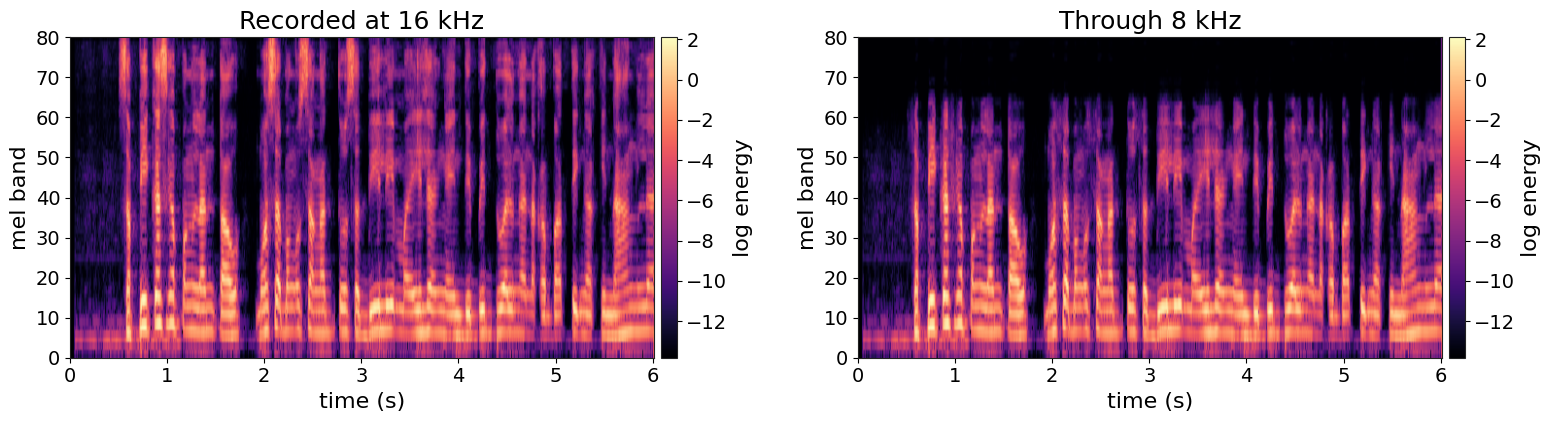

In [7]:
back16 = torchaudio.functional.resample(clip8, 8_000, 16_000)  # same length, less detail

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
plot_mel(paminaw.log_mel(paminaw.mel_spectrogram(clip16)), title="Recorded at 16 kHz", ax=axes[0])
plot_mel(paminaw.log_mel(paminaw.mel_spectrogram(back16)), title="Through 8 kHz", ax=axes[1])
plt.tight_layout()
plt.show()

Share of energy above ~4 kHz: 16 kHz 2.76% · through 8 kHz 0.0135%


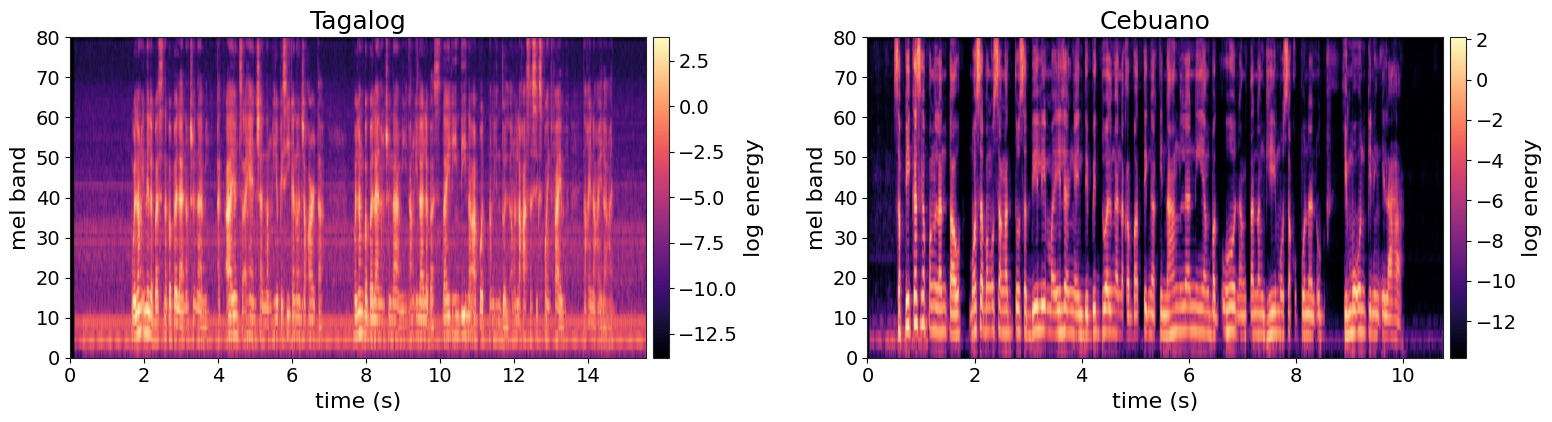

In [8]:
# Solution: how much energy is left above 4 kHz? (mel bands ≥ 60 of 80 ≈ above 4 kHz)
hi16 = paminaw.mel_spectrogram(clip16)[0, 60:].sum() / paminaw.mel_spectrogram(clip16)[0].sum()
hi8 = paminaw.mel_spectrogram(back16)[0, 60:].sum() / paminaw.mel_spectrogram(back16)[0].sum()
print(f"Share of energy above ~4 kHz: 16 kHz {hi16:.2%} · through 8 kHz {hi8:.4%}")

# Bonus: Tagalog vs Cebuano side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
plot_mel(paminaw.log_mel(paminaw.mel_spectrogram(wav_tl)), title="Tagalog", ax=axes[0])
plot_mel(paminaw.log_mel(paminaw.mel_spectrogram(wav_ceb)), title="Cebuano", ax=axes[1])
plt.tight_layout()
plt.show()

**Answer.** Everything above about 4 kHz (mel band ≈ 60 of 80) goes dark. A sample rate
of 8 kHz can only represent frequencies up to half that, 4 kHz (the *Nyquist* limit). A
model trained on 16 kHz audio, like Whisper, has never seen pictures with that hole, which
is one reason ASR does worse on phone recordings. Tagalog and Cebuano look alike as
pictures: same speakers' voices, same kinds of sounds. The difference is in the words,
which is why the language a model was trained on matters so much in Lab 2.

## 2 · Transcribe (about 30 minutes)

A speech recogniser (ASR) works in stages:
**audio** → 16 kHz tensor → **log-mel features** → **encoder** (turns the picture into a
sequence of vectors) → **decoder** (writes text one token at a time) → **text**.

**Whisper** (OpenAI) is an encoder-decoder trained on 680,000 hours of audio from the web.
Its vocabulary has a language token for Tagalog, `<|tl|>`, but **none for Cebuano**.

**Why PyTorch rather than TensorFlow?** Both can run speech models. But the open speech
models we use (Whisper, MMS and SeamlessM4T) are published as PyTorch weights. Hugging
Face `transformers` v5 supports PyTorch only. And `torchaudio` gives us audio loading and
features in the same tensor library.

In [9]:
import os

try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: Run cell 0 (Setup) at the top of the notebook first.") from None

# Lab 2 setup: safe to run even if you skipped the cells above
import time
from pathlib import Path

import pandas as pd
import torch
import transformers
from transformers import pipeline

from paminaw.asr import pick_device_dtype

transformers.logging.set_verbosity_error()  # hide library warnings; real errors still show
SMOKE_TEST = os.environ.get("PAMINAW_SMOKE") == "1"
paminaw.set_seed()
device, dtype = pick_device_dtype()  # ("cuda", float16) on a GPU, ("cpu", float32) otherwise
WHISPER_MODEL = "openai/whisper-tiny" if SMOKE_TEST else "openai/whisper-small"

# The one number to change: clips per language. 20 on CPU (about 10 minutes), 100 on a GPU.
N_CLIPS = 2 if SMOKE_TEST else (100 if device == "cuda" else 20)

tl = paminaw.load_subset("tagalog", n=N_CLIPS)
ceb = paminaw.load_subset("cebuano", n=N_CLIPS)
print(f"{WHISPER_MODEL} on {device} ({str(dtype).replace('torch.', '')}), "
      f"{N_CLIPS} clips per language")

openai/whisper-small on cpu (float32), 20 clips per language


In [10]:
# Download Whisper (about 1 GB for whisper-small; Colab's network is fast) and build a pipeline.
# chunk_length_s=30: Whisper hears at most 30 s at a time; 6 of our clips are a little longer.
asr = pipeline("automatic-speech-recognition", model=WHISPER_MODEL, device=device, dtype=dtype,
               chunk_length_s=30)

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

In [11]:
wav = paminaw.load_16k_mono(tl.path[0])

with torch.inference_mode():  # we only predict, so skip gradient bookkeeping
    out = asr({"raw": wav.squeeze(0).numpy(), "sampling_rate": 16_000},
              generate_kwargs={"language": "tagalog", "task": "transcribe"})

print("REFERENCE :", tl.transcription[0])
print("WHISPER   :", out["text"])

REFERENCE : walang inilabas na babala ng tsunami at ayon sa ahensiya ng heopisika ng jakarta walang babala ng tsunami ang ilalabas dahil hindi naabot ng lindol ang lakas na 6.5 na kinakailangan
WHISPER   :  Walang inilabas na babala ng tsunami at ayon sa ahensyan ng Hyopisika ng Jakarta. Walang babala ng tsunami ang ilalabas dahil hindi naabot ng lindul ang alakas na 6.5 na kinakailangan.


### Transcribe all clips

We pass `language="tagalog"` for the Cebuano clips too. Whisper has no Cebuano option, so
Tagalog is the nearest language it is allowed to write; the paper calls this the
*language-committed* condition. Results are saved to `outputs/` for Lab 3.

In [12]:
rows, t0, audio_seconds = [], time.perf_counter(), 0.0
for lang, clips in [("tagalog", tl), ("cebuano", ceb)]:
    for c in clips.itertuples():
        wav = paminaw.load_16k_mono(c.path)
        with torch.inference_mode():
            text = asr({"raw": wav.squeeze(0).numpy(), "sampling_rate": 16_000},
                       generate_kwargs={"language": "tagalog", "task": "transcribe"})["text"]
        rows.append({"lang": lang, "idx": c.idx, "fleurs_id": c.fleurs_id,
                     "hypothesis": text, "reference": c.transcription})
        audio_seconds += c.duration_s
        if len(rows) % 10 == 0 or len(rows) == 2 * N_CLIPS:
            print(f"{len(rows)} of {2 * N_CLIPS} clips done ({time.perf_counter() - t0:.0f} s)")
seconds = time.perf_counter() - t0
print(f"Transcribed {audio_seconds / 60:.1f} min of audio in {seconds:.0f} s "
      f"(real-time factor {seconds / audio_seconds:.2f}).")

mine = pd.DataFrame(rows)
Path("outputs").mkdir(exist_ok=True)
mine.to_csv("outputs/whisper_small_yours.csv", index=False)
pd.set_option("display.max_colwidth", 90)
mine[["lang", "reference", "hypothesis"]].groupby("lang").head(3)

10 of 40 clips done (146 s)


20 of 40 clips done (277 s)


30 of 40 clips done (418 s)


40 of 40 clips done (563 s)
Transcribed 11.1 min of audio in 563 s (real-time factor 0.85).


,lang,reference,hypothesis
0,tagalog,walang inilabas na babala ng tsunami at ayon sa ahensiya ng heopisika ng jakarta walan...,Walang inilabas na babala ng tsunami at ayon sa ahensyan ng Hyopisika ng Jakarta. Wal...
1,tagalog,ito ay nagsasaad na ang kadalasang epektibong lugar para sa pangunahing paksa ay nasa ...,Ito ay nagsasaad na ang kadalasang efektibong lugar para sa pangunahing paksa ay nasa...
2,tagalog,noong taong 1976 tatlumpung porsiyento ng machu picchu ang naisaayos at nagpapatuloy a...,Noong taong isang libo siyam nadaan at pitumput anim 30% ng Machu Picchu ang naisaayo...
20,cebuano,sa pikas nga panglantaw mausab ang usa ngadto sa dili mailhan nga indibidwal nga nakab...,"Sa picas ng panglantaw, mosa bang usangan to sa dili may ilan ng individual na nakaba..."
21,cebuano,ang populasyon sa siyudad sa batikano kay anaa sa mga 800. kini ang pinakagamay nga in...,"Ang populasyon sa studad sa batikano kaya naso mga utsusintos, kini ang pinakagamay a..."
22,cebuano,gikansela sa aerosmith ang ilang mga nahibiling mga konserto sa ilang panaw,Gikan sila sa Aerosmith ang ilang mga nahabiling mga konserto sa ilang panaw.


### Exercise 4 · Which language does Whisper hear?

Remove the language hint on a Cebuano clip and let Whisper decide. **Before you run it:**
what do you expect it to detect? Then read the **language token** Whisper chose.

In [13]:
samples = paminaw.load_16k_mono(ceb.path[0]).squeeze(0).numpy()

with torch.inference_mode():  # note: no "language" key this time
    no_hint = asr({"raw": samples, "sampling_rate": 16_000}, generate_kwargs={"task": "transcribe"})
print("REFERENCE (Cebuano):", ceb.transcription[0])
print("NO HINT            :", no_hint["text"])

# Ask Whisper directly which language token it would start with
features = asr.feature_extractor(samples, sampling_rate=16_000, return_tensors="pt")
with torch.inference_mode():
    lang_ids = asr.model.detect_language(features.input_features.to(device, dtype))
print("Detected language token:", asr.tokenizer.convert_ids_to_tokens(lang_ids.tolist()))
print("Does Whisper even have a Cebuano token?", "<|ceb|>" in asr.tokenizer.get_vocab())

REFERENCE (Cebuano): sa pikas nga panglantaw mausab ang usa ngadto sa dili mailhan nga indibidwal nga nakabati nga kinahanglan niyang bag-ohon ang tanang gihimo sa koponan ug himuon kining ilaha
NO HINT            :  Sa picas ng panglantaw, mosa bang usangan to sa dili may ilan ng individual na nakabatinga, kinahanglani ang baguhon ang tananghimo sa kupunan o himo'on kining ilaha.


Detected language token: ['<|tl|>']
Does Whisper even have a Cebuano token? False


In [14]:
# Solution: check all Cebuano clips, and compare with Whisper large-v3 from the paper's runs
detected = []
for p in ceb.path:
    w = paminaw.load_16k_mono(p).squeeze(0).numpy()
    f = asr.feature_extractor(w, sampling_rate=16_000, return_tensors="pt").input_features
    with torch.inference_mode():
        ids = asr.model.detect_language(f.to(device, dtype))
    detected += asr.tokenizer.convert_ids_to_tokens(ids.tolist())
print(f"{WHISPER_MODEL}, {len(detected)} Cebuano clips:", pd.Series(detected).value_counts().to_dict())

large = paminaw.load_precomputed("Whisper large-v3")
print("Whisper large-v3 (paper run), 100 Cebuano clips:",
      large[large.lang == "cebuano"]["detected_language"].value_counts().to_dict())

openai/whisper-small, 20 Cebuano clips: {'<|tl|>': 20}
Whisper large-v3 (paper run), 100 Cebuano clips: {'tl': 100}


**Answer.** Whisper detects **Tagalog** (`<|tl|>`). It has no Cebuano token at all, so the
nearest language it is allowed to write is the related Central Philippine language it
knows. In the paper, Whisper large-v3 chose Tagalog for **every one** of the 541 Cebuano
test clips, and the "with hint" and "no hint" runs came out byte-identical. Its Cebuano
errors are largely Tagalog words: Cebuano *nga* written as Tagalog *na*/*ng*, *tawo* as
*tao*, *dili* as *hindi*. Smaller Whisper models sometimes pick another language on a
clip, but never Cebuano.

## 2b · MMS-1B-all: a model that *does* know Cebuano (GPU runtimes)

**MMS** (Massively Multilingual Speech, Meta) is one shared wav2vec 2.0 model plus a small
**adapter** for each of 1,162 languages, including Cebuano (`ceb`) and Tagalog (`tgl`).
It is a **CTC** model: instead of writing word by word, it scores every letter (or a
"blank") for each 20 ms frame. We take the most likely one per frame (**argmax**), then
merge repeats and drop blanks.

### Three choices every time you run a model

| Choice | What we use | Why |
|---|---|---|
| **Device** | `cuda` if there is a GPU, else `cpu` | A GPU does thousands of multiplications at once. MMS has a billion parameters, so it only runs live on a GPU here. |
| **Precision** | `float16` for Whisper on a GPU; `float32` for MMS and anything on a CPU | Half precision halves memory and speeds up GPUs, but CPUs do not benefit. The MMS adapters are float32 weights, so the paper runs MMS in float32. |
| **`torch.inference_mode()`** | always, when transcribing | Training has to remember every step to compute gradients; inference does not. Switching that off saves memory and time. |

On a CPU runtime this lab loads the paper's precomputed MMS outputs for the same clips
instead.

In [15]:
import os

try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: Run cell 0 (Setup) at the top of the notebook first.") from None

import pandas as pd
import torch
import transformers
from transformers import AutoProcessor, Wav2Vec2ForCTC

transformers.logging.set_verbosity_error()  # hide library warnings; real errors still show
SMOKE_TEST = os.environ.get("PAMINAW_SMOKE") == "1"
paminaw.set_seed()
RUN_MMS = torch.cuda.is_available() and not SMOKE_TEST
N_MMS = 100 if RUN_MMS else 20
clips = {lang: paminaw.load_subset(lang, n=N_MMS) for lang in ("cebuano", "tagalog")}

if RUN_MMS:
    processor = AutoProcessor.from_pretrained("facebook/mms-1b-all")
    mms = Wav2Vec2ForCTC.from_pretrained("facebook/mms-1b-all", dtype=torch.float32).to("cuda")
    rows = []
    for lang, code in [("cebuano", "ceb"), ("tagalog", "tgl")]:
        processor.tokenizer.set_target_lang(code)  # the adapter's alphabet
        mms.load_adapter(code)  # swap in the language adapter (~2M parameters)
        mms.to("cuda")
        for c in clips[lang].itertuples():
            wav = paminaw.load_16k_mono(c.path).squeeze(0).numpy()
            inputs = processor(wav, sampling_rate=16_000, return_tensors="pt").to("cuda")
            with torch.inference_mode():
                logits = mms(**inputs).logits
            ids = torch.argmax(logits, dim=-1)[0]  # best letter per 20 ms frame
            rows.append({"lang": lang, "idx": c.idx, "hypothesis": processor.decode(ids)})
    mms_out = pd.DataFrame(rows)
    print(f"MMS ran live on {torch.cuda.get_device_name(0)} for {len(mms_out)} clips.")
else:
    print("Note: no GPU (or smoke test): loading the paper's precomputed MMS-1B-all outputs "
          "for the same clips instead.")
    pre = paminaw.load_precomputed("MMS-1B-all")
    keys = pd.concat(clips.values())[["lang", "idx"]]
    mms_out = pre.merge(keys, on=["lang", "idx"])[["lang", "idx", "hypothesis"]]

ref = pd.concat(clips.values())[["lang", "idx", "transcription"]]
show = ref.merge(mms_out, on=["lang", "idx"]).rename(columns={"transcription": "reference"})
pd.set_option("display.max_colwidth", 90)
show[show.lang == "cebuano"].head(3)[["reference", "hypothesis"]]

Note: no GPU (or smoke test): loading the paper's precomputed MMS-1B-all outputs for the same clips instead.


,reference,hypothesis
0,sa pikas nga panglantaw mausab ang usa ngadto sa dili mailhan nga indibidwal nga nakab...,sa pikas nga panglantaw mausab ang usa ngadto sa dili mailhan nga indibidwal nga nakab...
1,ang populasyon sa siyudad sa batikano kay anaa sa mga 800. kini ang pinakagamay nga in...,ang populasyon sa siyudad sa vaticano kay anaa sa mga 8s s0o kini ang pinakagamay nga ...
2,gikansela sa aerosmith ang ilang mga nahibiling mga konserto sa ilang panaw,gikan sela sa airosmith ang ilang mga nahabiling mga konserto sa ilang panaw


## 3 · Score (about 20 minutes)

**WER** (word error rate) counts the **s**ubstitutions, **d**eletions and **i**nsertions
needed to turn the model's words into the reference words, divided by the number of
reference words: WER = (S + D + I) / N. It can go above 100% when a model adds many extra
words. **CER** does the same with characters.

Before comparing, texts are usually **normalised**: lowercased, punctuation removed, and
so on. *How* you normalise is a choice. The paper behind this workshop (Golosino, Morales
& Adlaon 2026) shows that this choice alone moves Whisper's Tagalog WER by 15 points and
can change which model ranks first.

In [16]:
import os

try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: Run cell 0 (Setup) at the top of the notebook first.") from None

# Lab 3 setup: safe to run even if you skipped Labs 1 and 2
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from paminaw.compare import (PAPER_TABLE3_WER, convention_table, ranking_table,
                             score_systems, top_substitutions)
from paminaw.plotting import plot_convention_bars, set_style

SMOKE_TEST = os.environ.get("PAMINAW_SMOKE") == "1"
paminaw.set_seed()
set_style()
pd.set_option("display.max_colwidth", 90)
refs = paminaw.load_manifest()  # the 200 references (FLEURS "transcription" field)

MINE = Path("outputs/whisper_small_yours.csv")
if MINE.exists():
    mine = pd.read_csv(MINE, keep_default_na=False)
    source = "your Lab 2 run"
else:  # skipped Lab 2: use a ready-made Whisper-small run on the same clips
    n = 2 if SMOKE_TEST else 20
    mine = pd.read_csv(paminaw.data.data_file("precomputed/whisper-small.csv"),
                       keep_default_na=False).rename(columns={"hypothesis_raw": "hypothesis"})
    mine = mine.groupby("lang").head(n)
    source = "a ready-made Whisper-small run (you skipped Lab 2)"
n_mine = mine.groupby("lang").size().min()
print(f"Whisper-small outputs: {len(mine)} clips from {source}.")

Whisper-small outputs: 40 clips from your Lab 2 run.


### Exercise 5 · Write `normalize()` yourself

The paper's **primary** convention has four steps:
1. Unicode **NFC** (so `ñ` is always one character, never `n` + a separate tilde)
2. **case-fold** (lowercase, done properly for every language)
3. replace every character that is not a letter, digit, `_` or space **with a space**
4. **collapse** runs of spaces into one, and trim the ends

Steps 1 and 2 are done. Finish steps 3 and 4 (hint: `re.sub`), then run the check below.

In [17]:
import re
import unicodedata


def normalize(text):
    text = unicodedata.normalize("NFC", text)  # 1. compose characters
    text = text.casefold()  # 2. lowercase
    text = re.sub(r"[^\w\s]", " ", text)  # 3. punctuation → space
    text = re.sub(r"\s+", " ", text).strip()  # 4. collapse spaces
    return text

In [18]:
examples = ["Maayong buntag, Doc!", "Kumusta  ka na?", "Sen\u0303or N\u0303ino",
            "ang populasyon kay 800. kini", "bag-ohon"]
for ex in examples:
    ok = normalize(ex) == paminaw.normalize(ex, "primary")
    hint = "" if ok else f"   (expected {paminaw.normalize(ex)!r})"
    print("PASS" if ok else "FAIL", f"{ex!r:34} → {normalize(ex)!r}{hint}")
print("\nFrom here on we use paminaw.normalize, which also has the other three conventions.")

PASS 'Maayong buntag, Doc!'             → 'maayong buntag doc'
PASS 'Kumusta  ka na?'                  → 'kumusta ka na'
PASS 'Señor Ñino'                     → 'señor ñino'
PASS 'ang populasyon kay 800. kini'     → 'ang populasyon kay 800 kini'
PASS 'bag-ohon'                         → 'bag ohon'

From here on we use paminaw.normalize, which also has the other three conventions.


### Two worked examples

**1 · `kumusta ka na` → `kumusta kana`.** The model merged two words. That is one
substitution (*ka* → *kana*) plus one deletion (*na*) over 3 reference words:
WER = **2/3**. What about CER? It depends on a definition most people never look at:

* `jiwer.cer`, the library default, **counts spaces as characters**: 13 reference
  characters and one missing space, so CER = **1/13 ≈ 7.7%**.
* The paper computes CER over **non-whitespace characters only**: `kumustakana` against
  `kumustakana` is 0 errors out of 11, so CER = **0/11 = 0%**.

Same strings, two "correct" CERs. Just like normalisation, the definition has to be
stated next to the number.

**2 · `Maayong buntag, Doc!` → `maayong buntag doc`.** Every word differs if you compare
exactly as written, so WER = **100%** under `none`. After the primary normalisation the
texts are identical, so WER = **0%**.

In [19]:
ref, hyp = "kumusta ka na", "kumusta kana"
print(f"WER                          : {paminaw.wer(ref, hyp):.4f}  (2/3 = {2 / 3:.4f})")
print(f"CER, jiwer default (spaces)  : {paminaw.cer_jiwer_default(ref, hyp):.4f}  (1/13 = {1 / 13:.4f})")
print(f"CER, paper (no whitespace)   : {paminaw.cer(ref, hyp):.4f}  (0/11)")

ref, hyp = "Maayong buntag, Doc!", "maayong buntag doc"
pd.DataFrame(
    [{"convention": c, "reference": paminaw.normalize(ref, c), "hypothesis": paminaw.normalize(hyp, c),
      "WER %": 100 * paminaw.wer(paminaw.normalize(ref, c), paminaw.normalize(hyp, c))}
     for c in paminaw.CONVENTIONS]
).round(1)

WER                          : 0.6667  (2/3 = 0.6667)
CER, jiwer default (spaces)  : 0.0769  (1/13 = 0.0769)
CER, paper (no whitespace)   : 0.0000  (0/11)


,convention,reference,hypothesis,WER %
0,none,"Maayong buntag, Doc!",maayong buntag doc,100.0
1,casefold,"maayong buntag, doc!",maayong buntag doc,66.7
2,primary,maayong buntag doc,maayong buntag doc,0.0
3,strict,maayong buntag doc,maayong buntag doc,0.0


### Your Whisper-small: raw vs normalised

The FLEURS references are lowercase with almost no punctuation. Whisper writes capitals
and punctuation. Watch what that does to the score.

In [20]:
mine_sys = mine.assign(system="Whisper-small (yours)")[["system", "lang", "idx", "hypothesis"]]
label = f"workshop subset ({n_mine} clips per language)"
s_mine = score_systems(refs, mine_sys, conventions=["none", "primary"], subset_label=label)
print(f"Scores on the {label}; not the paper's full-split numbers.")
s_mine.pivot_table(index="lang", columns="convention", values=["wer", "cer"]).round(1)

Scores on the workshop subset (20 clips per language); not the paper's full-split numbers.


cer           wer        
convention  none primary  none primary
lang                                  
cebuano     14.2     9.6  61.0    49.1
tagalog     13.3     9.5  35.7    24.5

### The paper's three systems, four conventions

These are the paper's own, unnormalised outputs from Whisper large-v3, MMS-1B-all and
SeamlessM4T v2 Large for the **same 200 clips**. Nothing is re-run: only the scoring
changes.

In [21]:
pre = paminaw.load_precomputed()
scores = score_systems(refs, pre, subset_label="workshop subset (100 clips)")
print("WER (%) on the workshop subset (100 clips per language):")
convention_table(scores, "wer")

WER (%) on the workshop subset (100 clips per language):


convention                     none  casefold  primary  strict  sensitivity
system               lang                                                  
MMS-1B-all           cebuano  14.89     14.89    13.89   13.60         1.30
                     tagalog  14.10     14.10    13.51   12.69         1.41
SeamlessM4T v2 Large cebuano  41.91     37.88    37.72   38.00         4.18
                     tagalog  25.42     21.94    21.35   21.52         4.07
Whisper large-v3     cebuano  54.07     47.04    40.60   40.65        13.47
                     tagalog  26.12     19.01    11.90   11.86        14.26

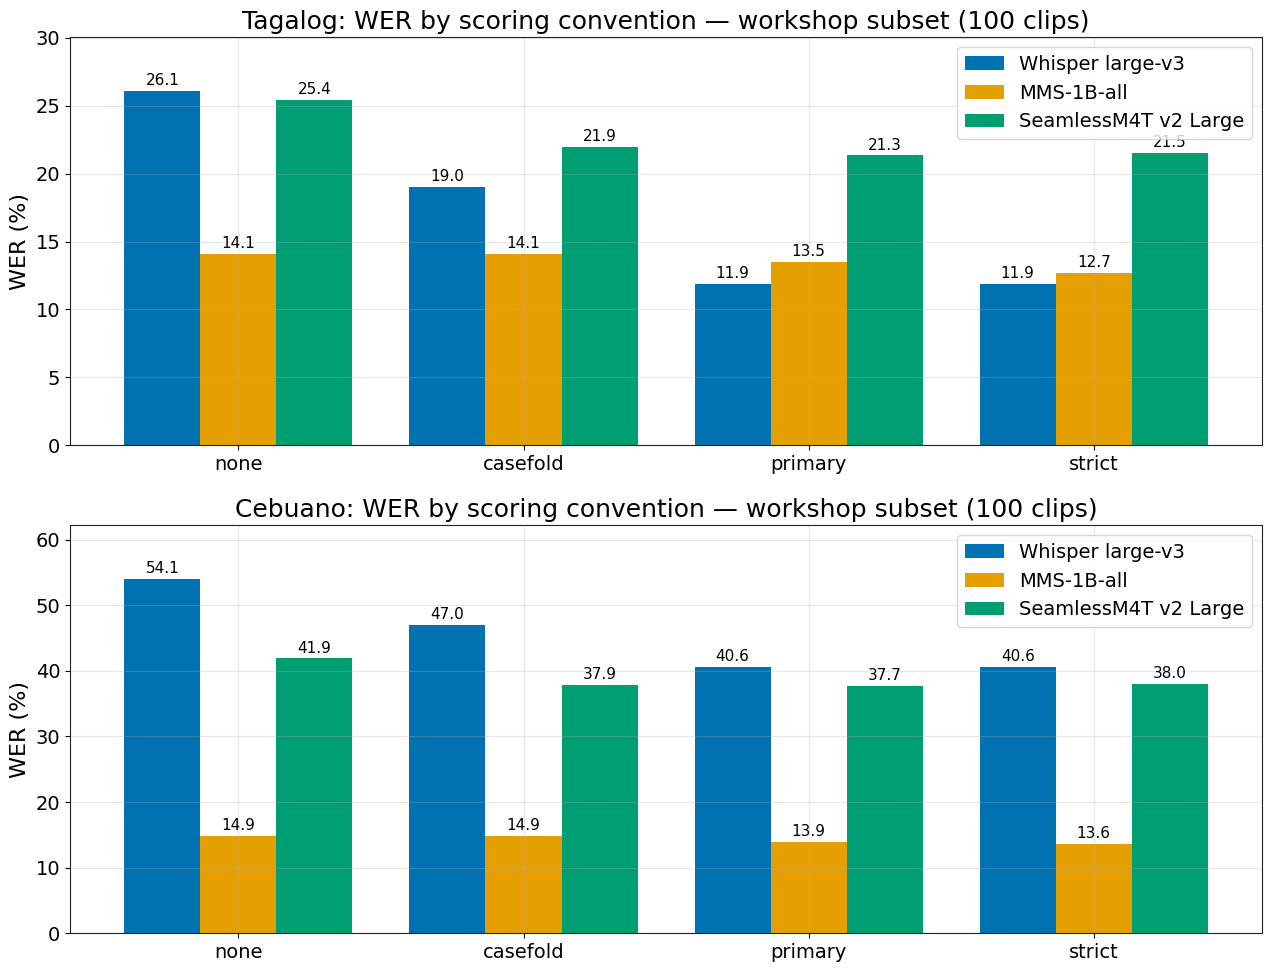

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, lang in zip(axes, ["tagalog", "cebuano"]):
    plot_convention_bars(scores, lang, ax=ax)
plt.tight_layout()
plt.show()

In [23]:
paper = pd.DataFrame(PAPER_TABLE3_WER).T
paper.index.names = ["system", "lang"]
print("For comparison, the paper's Table 3: WER (%) on the FULL test splits "
      "(964 Tagalog, 541 Cebuano utterances):")
paper

For comparison, the paper's Table 3: WER (%) on the FULL test splits (964 Tagalog, 541 Cebuano utterances):


none  casefold  primary  strict
system               lang                                     
Whisper large-v3     tagalog  27.11     19.12    12.23   12.14
                     cebuano  56.69     49.56    43.32   43.47
MMS-1B-all           tagalog  13.00     13.00    12.50   11.87
                     cebuano  14.47     14.47    13.62   13.46
SeamlessM4T v2 Large tagalog  25.26     21.09    20.51   20.41
                     cebuano  41.68     37.59    37.44   37.76

### Exercise 6 · Does the ranking change?

Rank 1 = lowest WER. Look along each language. **Question:** Under which convention would you pick a
different "best" model for Tagalog? Is any result on Cebuano robust to every convention?

In [24]:
ranking_table(scores, "wer")

system              MMS-1B-all  SeamlessM4T v2 Large  Whisper large-v3
lang    convention                                                    
cebuano none                 1                     2                 3
        casefold             1                     2                 3
        primary              1                     2                 3
        strict               1                     2                 3
tagalog none                 1                     2                 3
        casefold             1                     3                 2
        primary              2                     3                 1
        strict               2                     3                 1

In [25]:
# Solution: print the order per convention, and flag changes
for lang in ["tagalog", "cebuano"]:
    orders = {}
    for conv in paminaw.CONVENTIONS:
        s = scores[(scores.lang == lang) & (scores.convention == conv)].sort_values("wer")
        orders[conv] = " < ".join(f"{r.system.split()[0]} {r.wer:.1f}" for r in s.itertuples())
    changed = len({o.split(" ")[0] for o in orders.values()}) > 1
    print(f"{lang.upper()}: winner {'CHANGES' if changed else 'stays the same'} across conventions")
    for conv, o in orders.items():
        print(f"   {conv:9} {o}")

TAGALOG: winner CHANGES across conventions
   none      MMS-1B-all 14.1 < SeamlessM4T 25.4 < Whisper 26.1
   casefold  MMS-1B-all 14.1 < Whisper 19.0 < SeamlessM4T 21.9
   primary   Whisper 11.9 < MMS-1B-all 13.5 < SeamlessM4T 21.3
   strict    Whisper 11.9 < MMS-1B-all 12.7 < SeamlessM4T 21.5
CEBUANO: winner stays the same across conventions
   none      MMS-1B-all 14.9 < SeamlessM4T 41.9 < Whisper 54.1
   casefold  MMS-1B-all 14.9 < SeamlessM4T 37.9 < Whisper 47.0
   primary   MMS-1B-all 13.9 < SeamlessM4T 37.7 < Whisper 40.6
   strict    MMS-1B-all 13.6 < SeamlessM4T 38.0 < Whisper 40.6


**Answer.** On the full test split (paper, Sect. 4.2), Whisper large-v3 goes from **last**
on Tagalog under `none` (27.11) to **first** under `primary` (12.23, just ahead of MMS at
12.50). The scorer alone decides which of the two prints first. The two are statistically
indistinguishable on Tagalog. MMS barely moves, because its output has no capitals or
punctuation to normalise away.

On Cebuano, MMS beats Whisper under **every** convention by a margin no scoring choice
comes close to. That difference is real; the Tagalog one is not.

Your subset numbers will differ a little from the full split; 100 clips is a small
sample. Check whether the same pattern shows.

## Wrap-up: where the models fall short

* **Language coverage beats size.** Whisper large-v3 (1.55 B parameters) has no Cebuano
  token and degrades from 12 % to 43 % WER going from Tagalog to Cebuano. MMS (1 B
  parameters) declares Cebuano and barely moves (12.5 % → 13.6 %).
* **It writes the nearest language it knows.** Below are Whisper large-v3's most frequent
  Cebuano → Tagalog substitutions on our subset.
* **Read speech is the easy case.** FLEURS sentences are read aloud from prepared text, so
  these numbers are an upper bound. Spontaneous, code-switched Cebuano–Tagalog–English
  speech is much harder, and there is not yet a public benchmark for it.
* **Scoring is part of the result.** Always report the normalisation convention and
  which CER definition you used.

**What fine-tuning involves.** Collect transcribed audio in the target language (hours,
not thousands of hours), then train only a small part of the model. For MMS that is a new
**adapter** of about 2 M parameters, while the billion shared weights stay frozen. Hugging
Face has a step-by-step guide: [Fine-tuning MMS adapter models](https://huggingface.co/blog/mms_adapters).

**Links**
* Paper data, hypotheses and scoring code: [Zenodo 10.5281/zenodo.23010849](https://doi.org/10.5281/zenodo.23010849)
* Workshop repository: <https://github.com/GNash19/paminaw> (questions → Issues)

*Salamat kaayo! Maraming salamat!*

In [26]:
import os

try:
    import paminaw
except ModuleNotFoundError:
    raise SystemExit("Error: Run cell 0 (Setup) at the top of the notebook first.") from None

import pandas as pd
from paminaw.compare import top_substitutions

large = paminaw.load_precomputed("Whisper large-v3")
ceb_refs = paminaw.load_manifest("cebuano")
both = ceb_refs.merge(large[large.lang == "cebuano"], on=["lang", "idx"])
print("Whisper large-v3 on 100 Cebuano clips: most frequent word substitutions "
      "(reference → output)")
top_substitutions(both["transcription"], both["hypothesis"], n=10)

Whisper large-v3 on 100 Cebuano clips: most frequent word substitutions (reference → output)


,reference,hypothesis,count
0,nga,na,58
1,nga,ng,38
2,ug,at,24
3,ug,o,22
4,og,o,18
5,og,at,13
6,kon,kung,10
7,usab,usap,9
8,niini,ini,5
9,usa,sa,4
